# **Εργασία 4**

(1)

In [5]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split

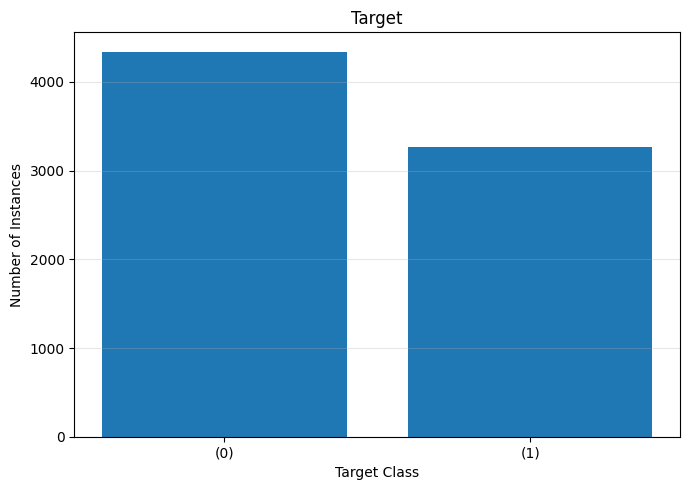

In [6]:
#Αρχίκα διαβάζουμε το αρχείο μας και στην συνέχεια κανουμε διαχωρισμό 90%-10% με stratify
df = pd.read_csv("train.csv")
X = df.drop("target", axis=1)
y = df["target"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.10,
    stratify=y,
    random_state=0
)

target_counts = df['target'].value_counts().sort_index()

plt.figure(figsize=(7, 5))

plt.bar(
    ['(0)', '(1)'],
    target_counts.values
)

plt.title('Target')
plt.xlabel('Target Class')
plt.ylabel('Number of Instances')

plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()


0: Δεν αναφέρεται πραγματική καταστροφή.

1: Αναφέρεται πραγματική καταστροφή.

Παρατηρούμε οτι η κλάση 0 υπερτέρει της κλάσεως 1 κάτα 1000 tweets , επομένως υπάρχει μια ένδειξη για ανισορροπία χωρίς όμως να παρατηρείται έντονη όμως.

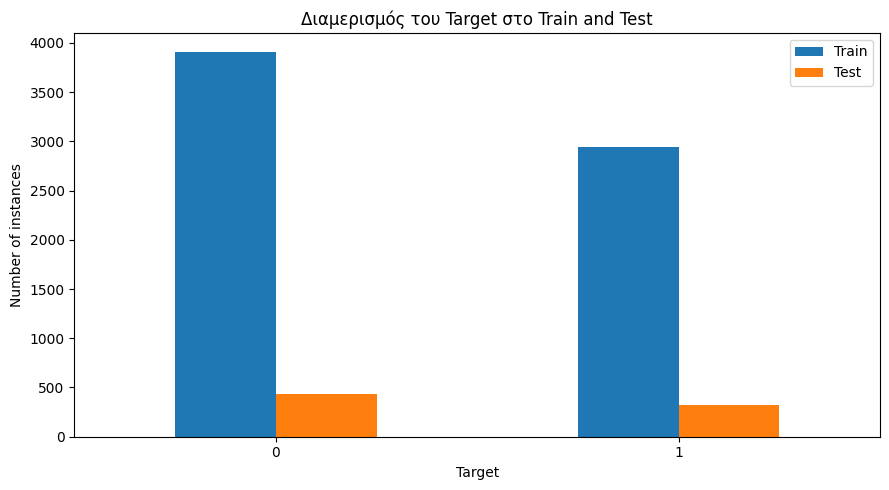

In [7]:
#Bar plot
fig, ax = plt.subplots(figsize=(9, 5))


pd.DataFrame({
    "Train": y_train.value_counts(),
    "Test": y_test.value_counts()
}).sort_index().plot(kind="bar", ax=ax)

plt.title("Διαμερισμός του Target στο Train and Test")
plt.xlabel("Target")
plt.ylabel("Number of instances")
plt.xticks(rotation=0)
plt.legend()
plt.tight_layout()
plt.show()


το dataset παρουσιάζει ήπια ανισορροπία μεταξύ των δύο κλάσεων. Με τη χρήση της παραμέτρου stratify, διατηρείται η αρχική κατανομή των κλάσεων στα σύνολα εκπαίδευσης και δοκιμής, εξασφαλίζοντας έναν αντιπροσωπευτικό διαχωρισμό των δεδομένων.


(2)

In [8]:

#αφαιρούμε id και location
df = df.drop(columns=['id', 'location'])

#Αντικατάσταση 'null'
df = df.fillna('null')

#κάνουμε συνένωση των keyword και text
df['inputs'] = df['keyword'] + ' ' + df['text']

#αποτελέσματα
print(df.head())

  keyword                                               text  target  \
0    null  Our Deeds are the Reason of this #earthquake M...       1   
1    null             Forest fire near La Ronge Sask. Canada       1   
2    null  All residents asked to 'shelter in place' are ...       1   
3    null  13,000 people receive #wildfires evacuation or...       1   
4    null  Just got sent this photo from Ruby #Alaska as ...       1   

                                              inputs  
0  null Our Deeds are the Reason of this #earthqu...  
1        null Forest fire near La Ronge Sask. Canada  
2  null All residents asked to 'shelter in place'...  
3  null 13,000 people receive #wildfires evacuati...  
4  null Just got sent this photo from Ruby #Alask...  


In [9]:
train = X_train.copy()
train['target'] = y_train

test = X_test.copy()
test['target'] = y_test

# Δημιουργία της στήλης inputs
train['inputs'] = train['keyword'] + ' ' + train['text']
test['inputs'] = test['keyword'] + ' ' + test['text']

Κατέβαζουμε τα αρχεία techniques.py  από το repository και τοποθέτουμε τα στον ίδιο φάκελο με το notebook μας

Καθώς θα χρησιμοποιήσουμε απο αυτο αρκετές οπως removeUnicode(), replaceURL(), replaceAtUser(), removeEmoticons() , replaceMultiExclamationMark() κ.τ.λ

το συγκεκριμένο το παίρνουμε απο το github Dimitrios Effrosynidis και τα προσαρμόζουμε στα δικά μας

In [10]:
import re
import string


def removeUnicode(text):
    """Removes unicode strings and non-ASCII characters."""
    text = re.sub(r'(\\u[0-9A-Fa-f]+)', '', text)
    text = re.sub(r'[^\x00-\x7f]', '', text)
    return text


def replaceURL(text):
    """Replaces URL addresses with 'url'."""
    text = re.sub(
        r'((www\.[^\s]+)|(https?://[^\s]+))',
        'url',
        text
    )
    text = re.sub(r'#([^\s]+)', r'\1', text)
    return text


def replaceAtUser(text):
    """Replaces user mentions with 'atUser'."""
    text = re.sub(r'@[^\s]+', 'atUser', text)
    return text


def removeHashtagInFrontOfWord(text):
    """Removes hashtag symbol in front of a word."""
    text = re.sub(r'#([^\s]+)', r'\1', text)
    return text


def replaceMultiExclamationMark(text):
    """Replaces repeated exclamation marks."""
    text = re.sub(r'(!)\1+', ' multiExclamation ', text)
    return text


def replaceMultiQuestionMark(text):
    """Replaces repeated question marks."""
    text = re.sub(r'(\?)\1+', ' multiQuestion ', text)
    return text


def replaceMultiStopMark(text):
    """Replaces repeated full stops."""
    text = re.sub(r'(\.)\1+', ' multiStop ', text)
    return text


def removeEmoticons(text):
    """Removes emoticons from text."""
    pattern = (
        r':\)|;\)|:-\)|\(-:|:-D|=D|:P|xD|X-p|\^\^|:-*|'
        r'\^\.\^|\^\-\^|\^\_\^|\,\-\)|\)-:|:\'\(|:\(|'
        r':-\(|:\S|T\.T|\.\_\.|:<|:-\S|:-<|\*\-\*|'
        r':O|=O|=\-O|O\.o|XO|O\_O|:-\@|=/|:/|X\-\(|'
        r'>\.<|>=\(|D:'
    )
    return re.sub(pattern, '', text)


In [11]:
# Συνάρτηση καθαρισμού κειμένου
def cleanourtext(text):
      # Αν υπάρχει κενή τιμή, την αντικαθιστούμε
    if pd.isna(text):
        text = ""

    #Αφαίρεση Unicode και θορύβου
    text = removeUnicode(text)

    #Αντικατάσταση URLs
    text = replaceURL(text)

    #Αντικατάσταση user mentions
    text = replaceAtUser(text)

    #Αφαίρεση του # από τα hashtags
    text = removeHashtagInFrontOfWord(text)

    #Αφαίρεση emoticons
    text = removeEmoticons(text)

    #Διαχείριση επαναλαμβανόμενων σημείων στίξης
    text = replaceMultiExclamationMark(text)
    text = replaceMultiQuestionMark(text)
    text = replaceMultiStopMark(text)

    #Μετατροπή σε πεζά
    text = text.lower()


    text = text.translate(
        str.maketrans('', '', string.punctuation)
    )

    text = re.sub(r'\s+', ' ', text).strip()

    return text


train['inputs'] = train['inputs'].apply(cleanourtext)
test['inputs'] = test['inputs'].apply(cleanourtext)

print("Train:")
print(train[['inputs', 'target']].head())

print("\nTest:")
print(test[['inputs', 'target']].head())

Train:
                                                 inputs  target
6669  threat meek mill responds to drakes ovo fest s...       1
3940  flood survived the plague floated the flood ju...       0
7217  weapons kick hendrixonfire atuser big noob con...       0
2234  deluge vince mcmahon once again a billionaire ...       0
4233  hazardous is it possible to sneak into a hospi...       0

Test:
                                                 inputs  target
604   bioterror fedex no longer to transport bioterr...       1
5374  panic panic over patient in alabama tests nega...       1
3022  dust20storm new mad max screenshots show off a...       0
3357  evacuated rocky fire in northern california sw...       1
4726  lava atuser lava blast amp power red atuser at...       0


removeUnicode: Αφαιρεί χαρακτήρες Unicode και μη λατινικούς χαρακτήρες

replaceURL: Αντικαθιστά url με μια ενιαία λέξη.



replaceAtUser: Αντικαθιστά τις αναφορές χρηστών (@user)


removeHashtagInFrontOfWord: Αφαιρεί το σύμβολο # από τα hashtags.



removeEmoticons: Αφαιρεί emoji.



replaceMultiExclamationMark: Αντικαθιστά τα διαδοχικά θαυμαστικά με μια ενιαία ένδειξη


replaceMultiQuestionMark: Αντικαθιστά τα επαναλαμβανόμενα ερωτηματικά με μια ενιαία ένδειξη



replaceMultiStopMark: Αντικαθιστά τις διαδοχικές τελείες με μια ενιαία ένδειξη.



lowercase: Μετατρέπει όλους τους χαρακτήρες σε πεζά


Αφαίρεση σημείων στίξης: Αφαιρεί τα περιττά σημεία στίξης



Αφαίρεση περιττών split: Συμπτύσσει τα πολλαπλά κενά σε ένα

(4)

χωρίζουμε το train test σε inputs και target και μετα εκτυπώνουμε τις διαστάσεις τους.

In [12]:
import numpy as np

#Διαχωρισμός των δεδομένων σε inputs και targets
train_inputs = train['inputs'].to_numpy()
train_targets = train['target'].to_numpy()

test_inputs = test['inputs'].to_numpy()
test_targets = test['target'].to_numpy()

In [13]:
print("Train inputs:", train_inputs.shape)
print("Train targets:", train_targets.shape)

print("Test inputs:", test_inputs.shape)
print("Test targets:", test_targets.shape)

Train inputs: (6851,)
Train targets: (6851,)
Test inputs: (762,)
Test targets: (762,)


(5)

μέθοδο TF-IDF και την κλάση TfidfVectorizer

In [14]:
from sklearn.feature_extraction.text import TfidfVectorizer

In [15]:
#TF-IDF Vectorizer
vectorizer = TfidfVectorizer()

#train set μετατροπη
train_inputs_tfidf = vectorizer.fit_transform(train_inputs)

#μετατροπή του test set με βάση το λεξιλόγιο του train
test_inputs_tfidf = vectorizer.transform(test_inputs)

In [17]:
print("Train shape:", train_inputs_tfidf.shape)
print("Test shape:", test_inputs_tfidf.shape)

print("head 5 λέξεις του λεξιλογίου ")
print(vectorizer.get_feature_names_out()[:5])

Train shape: (6851, 14625)
Test shape: (762, 14625)
head 5 λέξεις του λεξιλογίου 
['0011' '001116' '0025' '005225' '010156']


(6)

Για να εκπαιδεύσουμε τον ταξινομητή Gaussian Naive Bayes, θα χρησιμοποιήσουμε τα TF-IDF δεδομένα

 ταξινομητή Gaussian Naive Bayes απο sklearn


In [19]:
from sklearn.naive_bayes import GaussianNB
gnb = GaussianNB() #Gaussian Naive Bayes

X_train_dense = train_inputs_tfidf.toarray()
X_test_dense = test_inputs_tfidf.toarray()

#κανουμε train τον ταξινομητη
gnb.fit(X_train_dense, train_targets)

GaussianNB()

In [23]:
#κάνουμε πρόβλεψη
y_pred = gnb.predict(X_test_dense)

print("head 20 προβλέψεις:")
print(y_pred[:20])

head 20 προβλέψεις:
[1 0 0 1 1 0 1 0 1 0 0 0 1 1 1 0 1 1 0 1]


In [24]:
from sklearn.metrics import accuracy_score

accuracy = accuracy_score(test_targets, y_pred)

print("Gaussian Naive Bayes Accuracy:", accuracy)

Gaussian Naive Bayes Accuracy: 0.6286089238845144


Ο ταξινομητής Gaussian Naive Bayes πέτυχε ποσοστό ακρίβειας περίπου 62% στο test set.Το δεδομένο αποτέλεσμα δείχνει ότι το μοντέλο καταφέρνει να ταξινομήσει σωστά ένα μέρος των tweets, ωστόσο η συνολική του απόδοση είναι σχετικά χαμηλή